**Write the names of all group members (max. 5 members)**:
- Isabella Ceotto
- Giulio Tonielli
- Zhenbin Marco Fu
- Ariba Mbeche

When submitting your work, please follow closely the template below.

Implement the models from scratch using PyTorch (you may adapt `demo.ipynb`) or TensorFlow. Do not use third-party repositories containing ready-made deep hedging implementations. One submission per team is enough.

# Exercise 1

### Question 1.a

Use Itô’s formula to check that $S_t=s_0\exp(\sigma W_t-\frac12\sigma^2t)$ solves the Black–Scholes SDE with $r=0$. 

PROOF: Our goal is to show that $S_t = s_0 \exp\left(\sigma W_t - \tfrac12 \sigma^2 t\right)$ solves the Black–Scholes SDE with $r=0$:        $$ dS_t = \sigma S_t \, dW_t, \qquad S_0 = s_0 . $$

First of all, we write $S_t$ as a function of $(t, W_t)$. To simplify the notation, we define:
$$
f(t,w) = s_0 \exp\left(\sigma w - \tfrac12 \sigma^2 t\right),
$$
so that $S_t = f(t, W_t)$. We can apply Itô's formula since the function $f$ is $C^{1,2}$ (once continuously differentiable in $t$, twice in $w$). (Side note: the function $f$ is actually $C^\infty$)

We recall the key property of Brownian motion. Since $W_{t+\Delta t} - W_t \sim \mathcal{N}(0, \Delta t)$, the squared increment has size $\Delta t$, which gives the rule $(dW_t)^2 = dt$. So the second-order term $\tfrac12 \frac{\partial^2 f}{\partial w^2}(dW_t)^2$ cannot be neglected, and this is the extra term in Itô's formula, which for $W$ a standard Brownian motion and $f \in C^{1,2}$ reads:
$$
df(t,W_t) = \left( \frac{\partial f}{\partial t}(t,W_t) + \frac12 \frac{\partial^2 f}{\partial w^2}(t,W_t) \right) dt + \frac{\partial f}{\partial w}(t,W_t)\, dW_t .
$$

Then, we compute our function's partial derivatives (using our simplified notation):
$$
\frac{\partial f}{\partial t}(t,w) = -\tfrac12 \sigma^2 f(t,w), \qquad
\frac{\partial f}{\partial w}(t,w) = \sigma f(t,w), \qquad
\frac{\partial^2 f}{\partial w^2}(t,w) = \sigma^2 f(t,w).
$$
We substitute them into Itô's formula. Evaluating at $(t, W_t)$ and using $f(t,W_t) = S_t$ we obtain the following expression:
$$
dS_t = \left( -\tfrac12 \sigma^2 S_t + \tfrac12 \sigma^2 S_t \right) dt + \sigma S_t \, dW_t
= 0 \cdot dt + \sigma S_t \, dW_t .
$$
Hence
$$
dS_t = \sigma S_t \, dW_t ,
$$
which is the Black–Scholes SDE with $r=0$.

Lastly, we verify that the initial condition is satisfied.
Since $W_0 = 0$:
$$
S_0 = s_0 \exp(0 - 0) = s_0 .
$$

Since we have verified that $S_t = s_0 \exp\left(\sigma W_t - \tfrac12 \sigma^2 t\right)$ satisfies both the dynamics and the initial condition of the Black–Scholes SDE with $r=0$, we can conclude our proof.


### Question 1.b - Generate dataset

In [1]:
# Generate 100,000 training paths and 10,000 independent test paths.
# Parameters: N=30, s0=1, T=1/4 year, sigma=0.35, r=0.
# Use the exact geometric Brownian motion update specified in Problem 1(b).
# Each path contains N+1=31 prices, including S0 and ST.
import torch
import math

# Parameters
N = 30            # number of trading intervals
s0 = 1.0          # initial stock price
T = 0.25          # maturity: 3 months = 1/4 year
sigma = 0.35      # volatility

m_train = 100_000
m_test = 10_000

def simulate_gbm_paths(n_paths, N, s0, sigma, T, generator=None, dtype=torch.float32):
    """
    Exact simulation of geometric Brownian motion (r = 0):
        S_{t_{j+1}} = S_{t_j} * exp(-0.5*sigma^2*dt + sigma*sqrt(dt)*Z_{j+1})
        with dt = T/N and Z_{j+1} ~ N(0, 1) iid.
    Returns a tensor of shape (n_paths, N+1), including S_0 and S_T.
    """
    dt = T / N        # time step

    # N iid standard Gaussians per path. It generates a table with random gaussian
    # numbers, where a row is a path and each column is a time step.
    # Each entry is the random shock Z_{j+1} of that step on that path.
    Z = torch.randn(n_paths, N, generator=generator)

    # log-increments of each step: they are the exponent of the update formula.
    # Each price S_{t_j} is s0 times a product of exponentials. Taking logs
    # turns this product into a sum, which is easier to compute.
    log_increments = -0.5 * sigma**2 * dt + sigma * math.sqrt(dt) * Z

    # cumulative sum of log-increments -> log(S_{t_j} / s0) for j = 1,...,N
    log_paths = torch.cumsum(log_increments, dim=1)
    # dim=1 means that we compute along the columns, i.e. along the time axis.
    # A for loop would give the same result, but cumsum is faster.


    # prepend log(S_0/s0) = 0 so that each path has N+1 prices, including the initial
    # time t_0 = 0. This is equivalent to prepending a column of zeros to the log_paths tensor.
    log_paths = torch.cat([torch.zeros(n_paths, 1), log_paths], dim=1)
    return s0 * torch.exp(log_paths)

# Separate generators with different seeds, so that we obtain independent train and test sets
gen_train = torch.Generator().manual_seed(0)
gen_test = torch.Generator().manual_seed(1)

# Generate the training set
S_train = simulate_gbm_paths(m_train, N, s0, sigma, T, generator=gen_train)

# Generate the test set
S_test = simulate_gbm_paths(m_test, N, s0, sigma, T, generator=gen_test)

# Sanity checks
print("Train shape:", tuple(S_train.shape))   # (100000, 31)
print("Test shape: ", tuple(S_test.shape))    # (10000, 31)
print("All paths start at s0:", torch.all(S_train[:, 0] == s0).item())

# Check that the mean and std of the terminal prices are as expected. By Martingale property, E[S_T] = S_0 * exp(r*T) = S_0 since r=0.
# By the properties of geometric Brownian motion, log(S_T) is normally distributed with mean log(S_0) - 0.5*sigma^2*T and variance sigma^2*T. 
# Therefore, the std of log(S_T) should be sigma*sqrt(T).
print(f"Mean of S_T (should be ~ {s0}): {S_train[:, -1].mean().item():.4f}")
print(f"Std of log(S_T) (should be ~ {sigma*math.sqrt(T):.4f}): "
      f"{torch.log(S_train[:, -1]).std().item():.4f}")

Train shape: (100000, 31)
Test shape:  (10000, 31)
All paths start at s0: True
Mean of S_T (should be ~ 1.0): 0.9992
Std of log(S_T) (should be ~ 0.1750): 0.1750


***Question 1.b***

From Question 1.a, taking the ratio of $S_t$ at two consecutive grid points and using $W_{t_{j+1}} - W_{t_j} = \sqrt{T/N}\, Z_{j+1}$ with $Z_j$ iid $\mathcal{N}(0,1)$, we get the exact update
$$
S_{t_{j+1}} = S_{t_j} \exp\left( -\frac{\sigma^2}{2}\frac{T}{N} + \sigma \sqrt{\frac{T}{N}}\, Z_{j+1} \right),
$$
which has no discretization error. We implement it with a cumulative sum of log-increments and prepend $S_{t_0} = s_0$, so each path has $N+1 = 31$ prices. Train and test sets are generated with different seeds, so they are independent.

Sanity checks: the empirical mean of $S_T$ is $0.9992 \approx 1$ (martingale property) and the standard deviation of $\log S_T$ is $0.1750 \approx \sigma\sqrt{T}$, as expected.

### Question 1.c - Model implementation

In [2]:
# Implement the deep hedging model from scratch.
# You may use and edit the code shown in demo.ipynb.
# Create 30 separate networks H_0,...,H_29, each with its own parameters.
# Each network takes the current stock price as input and returns the shares to hold.
# Do not use future prices as inputs to the trading decision.

import torch
import torch.nn as nn

# Fix the seed so that the random initial weights of the networks are reproducible.
torch.manual_seed(42)

# Number of neurons in hidden layers (as in demo.ipynb): 32 neurons per layer are enough
# to approximate a smooth 1D function like the call delta, while keeping 30 networks cheap to train.
nh1 = 32   # first hidden layer
nh2 = 32   # second hidden layer

def make_hedge_network(nh1, nh2):
    """
    One feedforward network H_j : R -> R (same architecture as in demo.ipynb).
    Input: current stock price S_{t_j}. Output: number of shares to hold on [t_j, t_{j+1}).
    """
    # Two hidden layers with ReLU activations: the non-linearity lets the network
    # approximate the S-shaped delta (without it, stacked linear layers would collapse
    # into a single linear map). The last layer has no activation, so the output
    # (number of shares) can be any real number.
    return nn.Sequential(nn.Linear(1, nh1),
                         nn.ReLU(),
                         nn.Linear(nh1, nh2),
                         nn.ReLU(),
                         nn.Linear(nh2, 1))

# We define a class (instead of a single nn.Sequential as in the demo) because the model
# combines 30 networks, each with a different input, and then the price increments.
class DeepHedgingModel(nn.Module):
    def __init__(self, N, nh1, nh2):
        super().__init__()   # required to initialize nn.Module
        self.N = N           # number of trading dates
        # One separate network per trading date t_j, each with its own parameters theta_j.
        # Time is encoded by the choice of the network, so each H_j only needs S_{t_j} as input.
        # nn.ModuleList (instead of a plain Python list) registers all parameters in the model,
        # so that model.parameters() returns them and the optimizer can train them jointly.
        self.networks = nn.ModuleList([make_hedge_network(nh1, nh2) for _ in range(N)])

    def holdings(self, S):
        """
        S: tensor of shape (batch, N+1) with prices S_{t_0},...,S_{t_N}.
        Returns a tensor of shape (batch, N): column j = H_j(S_{t_j}).
        """
        # Network j only receives column j, i.e. the price at time t_j: no future prices
        # are used (predictability). The last column S_T is never an input.
        # S[:, j:j+1] keeps the shape (batch, 1) required by nn.Linear(1, ...),
        # whereas S[:, j] would give a flat vector of shape (batch,).
        H = [self.networks[j](S[:, j:j+1]) for j in range(self.N)]   # each (batch, 1)
        # Put the N columns side by side: row = path, column = trading date.
        return torch.cat(H, dim=1)                                   # (batch, N)

    def forward(self, S):
        """
        Returns the trading gains sum_j H_j(S_{t_j}) * (S_{t_{j+1}} - S_{t_j}),
        one value per path: tensor of shape (batch,).
        """
        H = self.holdings(S)          # shares held on each interval, (batch, N)
        # Price increments S_{t_{j+1}} - S_{t_j}, aligned with the columns of H.
        dS = S[:, 1:] - S[:, :-1]     # (batch, N)
        # Element-wise product = gain on each interval; summing over time gives the
        # discrete stochastic integral approximating int H dS.
        # The model returns only the trading gains (the part that depends on the networks);
        # the premium p and the payoff g(S_T) are added in the loss in 1.d.
        return (H * dS).sum(dim=1)

# Instantiate the model: 30 networks with random initial weights (trained in 1.d).
model = DeepHedgingModel(N, nh1, nh2)

# Sanity checks: number of networks, number of parameters, and output shapes.
print("Number of networks:", len(model.networks))                         # 30
# Expected: (1*32+32) + (32*32+32) + (32*1+1) = 1153 parameters per network
print("Parameters per network:", sum(p.numel() for p in model.networks[0].parameters()))
# Expected: 30 * 1153 = 34590 -> confirms that ModuleList registered all networks
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Holdings shape on 5 paths:", tuple(model.holdings(S_train[:5]).shape))  # (5, 30)
print("Gains shape on 5 paths:   ", tuple(model(S_train[:5]).shape))          # (5,)

Number of networks: 30
Parameters per network: 1153
Total parameters: 34590
Holdings shape on 5 paths: (5, 30)
Gains shape on 5 paths:    (5,)


***Question 1.c***

We use $N = 30$ separate networks $H_0, \dots, H_{29}$, one per trading date, each with its own parameters. Network $H_j$ takes only the current price $S_{t_j}$ as input (predictability: no future prices) and returns the number of shares held on $[t_j, t_{j+1})$. Since the Black–Scholes model is Markovian, thus it only depends on the present status, the optimal hedge depends only on $(t_j, S_{t_j})$, and time is encoded by the choice of the network.

Each network has the architecture of `demo.ipynb` (two hidden layers with 32 neurons and ReLU), which is enough to approximate the smooth delta of a call. The model returns the trading gains $\sum_{j=0}^{N-1} H_j(S_{t_j})(S_{t_{j+1}} - S_{t_j})$; the premium $p$ and the payoff are added in the loss in Question 1.d, where all networks are trained jointly.

### Question 1.d - Model training

Black-Scholes premium p = C(0, s0) = 0.069726
Unhedged loss on test set (H = 0): 0.012965
Epoch  0: train = 1.726e-03, test = 5.369e-04
Epoch  5: train = 1.522e-04, test = 1.509e-04
Epoch 10: train = 1.363e-04, test = 1.420e-04
Epoch 15: train = 1.324e-04, test = 1.359e-04
Epoch 20: train = 1.325e-04, test = 1.396e-04
Epoch 25: train = 1.329e-04, test = 1.310e-04
Epoch 30: train = 1.219e-04, test = 1.243e-04
Epoch 35: train = 1.207e-04, test = 1.244e-04
Epoch 40: train = 1.208e-04, test = 1.249e-04
Epoch 45: train = 1.197e-04, test = 1.232e-04
Epoch 50: train = 1.195e-04, test = 1.233e-04
Epoch 55: train = 1.195e-04, test = 1.234e-04
Epoch 59: train = 1.195e-04, test = 1.233e-04
Final training loss: 1.195e-04
Final test loss:     1.233e-04


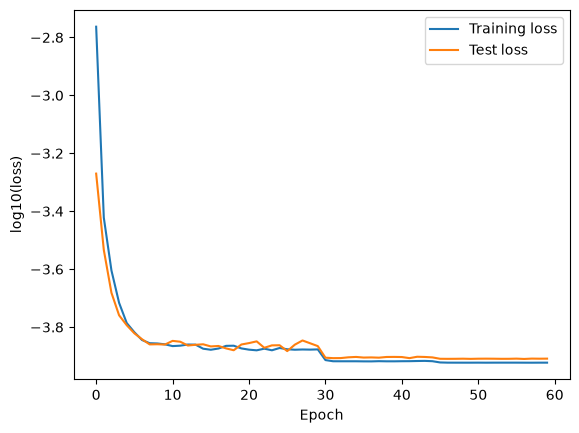

In [5]:
# Implement the call payoff with strike K=1 and maturity T=1/4 year.

# Implement the Black-Scholes call-price formula (3).
# Compute and fix the initial premium p=C(0,s0); p is not trained.

# Train all 30 networks jointly by minimizing equation (2) on the training set.

import torch
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

K = 1.0   # strike
r = 0.0   # risk-free rate (assumed zero, as in the problem statement)

# To evaluate how much the call option pays at maturity
def call_payoff(S_T, K):
    """g(S_T) = (S_T - K)^+ , computed element-wise on a tensor of terminal prices."""
    # torch.clamp(x, min=0) = max(x, 0) element-wise; we use a PyTorch operation (instead of
    # Python's max) so that it works on whole tensors and is compatible with autograd.
    return torch.clamp(S_T - K, min=0.0)

# Now we want to implement the Black-Scholes call price formula
# Standard normal distribution: its .cdf method is the function Phi in formula (3).
std_normal = torch.distributions.Normal(0.0, 1.0)

def bs_call_price(t, s, K, T, sigma, r=0.0):
    """
    C(t, s) = Phi(d+) * s - Phi(d-) * K * exp(-r (T - t)), for t < T.
    Works with tensors s (and scalar or tensor t), so it can be reused in 1.f and 1.g.
    """
    s = torch.as_tensor(s, dtype=torch.float32)                # convert input to a tensor
    tau = torch.as_tensor(T - t, dtype=torch.float32)          # time to maturity T - t
    d_plus = (torch.log(s / K) + (r + 0.5 * sigma**2) * tau) / (sigma * torch.sqrt(tau))
    d_minus = d_plus - sigma * torch.sqrt(tau)
    return std_normal.cdf(d_plus) * s - std_normal.cdf(d_minus) * K * torch.exp(-r * tau)

# Fixed premium p = C(0, s0)
# .item() turns it into a plain Python float, so it is a constant and NOT a trainable
# parameter: the optimizer only trains the networks, as required by the problem.
p = bs_call_price(0.0, s0, K, T, sigma, r).item()  # Evaluate the Black-Scholes price at t=0
print(f"Black-Scholes premium p = C(0, s0) = {p:.6f}")

# Reference value: loss of the unhedged position (H = 0), i.e. E[(p - g(S_T))^2].
# After training, the hedging loss must be much smaller than this, otherwise the
# networks are not hedging.
unhedged_loss = torch.mean((p - call_payoff(S_test[:, -1], K))**2).item()
print(f"Unhedged loss on test set (H = 0): {unhedged_loss:.6f}")

# Training setup
n_epochs = 60              # number of passes over the whole training set
lr = 5e-3                  # initial learning rate
batch_size = 1000          # paths per gradient step -> 100 steps per epoch
milestones = [30, 45]      # epochs at which the learning rate is divided by 10

# Re-create the model so that training always starts from fresh random weights,
# even if this cell is run more than once.
torch.manual_seed(42)
model = DeepHedgingModel(N, nh1, nh2)

# Adam optimizer on model.parameters(): thanks to nn.ModuleList this contains the
# parameters of all 30 networks, which are therefore trained jointly.
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

# Scheduler (as in demo.ipynb): large steps at the beginning to approach the minimum
# quickly, then smaller steps (lr * 0.1 at each milestone) to refine the solution.
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=milestones, gamma=0.1)

# Each sample is a whole path of 31 prices. Unlike the demo, there is no target y:
# in deep hedging the loss is computed directly from the paths.
# shuffle=True reshuffles the paths at every epoch, so batches are different each time.
loader = DataLoader(TensorDataset(S_train), batch_size=batch_size, shuffle=True)

def hedging_loss(model, S, p, K):
    """Empirical loss (2): mean over paths of (p + sum_j H_j(S_tj) dS_j - g(S_T))^2."""
    # P&L of the hedged position for each path:
    # premium + trading gains (computed by the model of 1.c) - payoff at maturity.
    # S[:, -1] is the last column, i.e. the terminal price S_T.
    pnl = p + model(S) - call_payoff(S[:, -1], K)
    # Mean squared hedging error: depends on all 30 networks through the terminal P&L.
    return torch.mean(pnl**2)

# Training 
train_losses = torch.empty(n_epochs)   # average training loss at each epoch
test_losses = torch.empty(n_epochs)    # test loss at each epoch (to monitor generalization)

for epoch in range(n_epochs):
    epoch_loss = 0.0
    # (S_batch,) : each element of the loader is a tuple with a single tensor (no target y)
    for (S_batch,) in loader:
        loss = hedging_loss(model, S_batch, p, K)   # loss on the current batch
        loss.backward()                              # gradients w.r.t. the parameters of all 30 networks
        optimizer.step()                             # one gradient step (update the weights)
        optimizer.zero_grad()                        # reset gradients, otherwise PyTorch accumulates them
        # accumulate the batch loss weighted by the batch size, to compute the epoch average
        epoch_loss += loss.item() * S_batch.shape[0]

    scheduler.step()   # update the learning rate according to the milestones

    # Average training loss over the epoch (more stable than the loss of the last batch).
    train_losses[epoch] = epoch_loss / len(S_train)
    # Test loss on the independent test paths: torch.no_grad() disables gradient
    # computation, since we only evaluate the model (faster and uses less memory).
    with torch.no_grad():
        test_losses[epoch] = hedging_loss(model, S_test, p, K).item()

    # Print progress every 5 epochs (and at the last epoch)
    if epoch % 5 == 0 or epoch == n_epochs - 1:
        print(f"Epoch {epoch:2d}: train = {train_losses[epoch].item():.3e}, "
              f"test = {test_losses[epoch].item():.3e}")

print(f"Final training loss: {train_losses[-1].item():.3e}")
print(f"Final test loss:     {test_losses[-1].item():.3e}")

# Plot of the losses in log scale, since they decrease by several orders of magnitude.
# If training and test losses decrease together and stay close, the learned strategy
# generalizes to unseen paths (no overfitting).
plt.plot(torch.log10(train_losses), label='Training loss')
plt.plot(torch.log10(test_losses), label='Test loss')
plt.xlabel('Epoch')
plt.ylabel('log10(loss)')
plt.legend()
plt.show()

***Question 1.d***

For the call we use the payoff $g(S_T) = (S_T - K)^+$ with $K = 1$. To get the premium we plug $t = 0$ and $s = s_0$ into the Black–Scholes formula, which for $r = 0$ becomes
$$
C(t, s) = \Phi(d_+)\, s - \Phi(d_-)\, K, \qquad d_\pm = \frac{\log(s/K) \pm \frac12 \sigma^2 (T-t)}{\sigma \sqrt{T-t}}.
$$
We get $p = 0.069726$. This value stays fixed during training, only the networks are optimized. Just to have something to compare with, we also computed the loss when we don't hedge at all ($H = 0$): on the test set it is $0.012965$.

Then we train the 30 networks together by minimizing
$$
\frac{1}{m} \sum_{i=1}^{m} \left( p + \sum_{j=0}^{N-1} H_j\big(s^{(i)}_{t_j}\big) \big(s^{(i)}_{t_{j+1}} - s^{(i)}_{t_j}\big) - g\big(s^{(i)}_T\big) \right)^2 .
$$
The main difference with the demo is that here we don't have a target to compare the output with: the loss only depends on the final P&L of each path, so every network affects it. We used Adam with learning rate $5\cdot 10^{-3}$, batches of 1000 paths and 60 epochs, and we lowered the learning rate by a factor 10 at epochs 30 and 45.

Looking at the plot, the loss goes down very fast in the first few epochs and after that it more or less stays flat. At epoch 30 there is a small jump down, which is when the learning rate gets reduced. At the end we have a training loss of $1.195\cdot 10^{-4}$ and a test loss of $1.233\cdot 10^{-4}$, so roughly 100 times smaller than without hedging. Since the two curves are almost on top of each other, we don't think the model is overfitting. The error that is left comes mostly from the fact that we can only rebalance at 30 dates and not continuously.

### Question 1.e - Model evaluation

In [ ]:
# Evaluate the trained hedge on the 10,000 independent test paths.
# Compute P&L = p + sum_j H_j(S_tj)*(S_tj+1-S_tj) - g(ST).
# Plot its histogram and print the empirical mean and standard deviation.

### Question 1.f(i) - Compute analytical solution

Show a **step-by-step** derivation of the analytical hedging strategy:

\begin{align*}
H^{\text{BS}}_t(s) & = \frac{\partial C(t, s)}{\partial s} \\
& = \ldots
\end{align*}

No points for solutions without explicit derivation.

### Question 1.f(ii) - P&L comparison with the analytical hedge

In [ ]:
# Implement the formula you found
# Rebalance at t_0,...,t_29 using the same test paths, premium and payoff as in 1.e.
# Compute P&L using the same sign convention as in 1.e.
# Plot histograms of both P&L distributions and print their means and standard deviations.

How does your deep hedging model compare with the analytical solution? If it's worse, you must improve its performance. A few questions for you to consider...

Have you trained your deep hedging model well?
- Are the losses centered on zero? ($10^{-5} \approx 0$)
- Is their standard deviation comparable with that of the analytical solution?

How can you improve performance?
- train for more epochs
- try a different learning rate
- change the networks' architectures (first try more hidden neurons, then try more hidden layers)
- try different batch sizes
- use a learning rate scheduler (see https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate)
- try a different activation function (e.g. $\tanh$)
- implement regularization (use the `weight_decay` argument in the optimizer)
- implement batch-normalization (see https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html)
- experiment with different optimizers
- ask in the forum

### Question 1.g - Learned strategy comparison with analytical solution

In [ ]:
# Compare the hedge functions at j=0,10,20,29.
# Make a grid of stock prices s in [0.5,1.5].
# Create four plots or panels, one per selected date.
# In each panel, overlay H_j(s) and the analytical delta evaluated on the same price grid.
# Label the date, both strategies, and axes (stock price and number of shares).

- For what times $t_j$ are the two functions most similar? 
- Why?

# Exercise 2

### Question 2.a - Generate dataset

In [ ]:
# Generate 100,000 training paths and 10,000 independent test paths of (S,V).
# Parameters: N=30, s0=1, T=1/4 year, rho=-0.3, a=4, b=0.5, v0=0.5, sigma=1.
# Each stock and variance path contains N+1=31 values.

# (i) Write a function to simulate V using the exact noncentral chi-square transitions.

# (ii) Write a function to simulate S using the supplied simplified Broadie-Kaya update.

### Question 2.b - Model implementation

In [ ]:
# Implement the deep hedging model for a generic AVaR level alpha.
# Create 30 separate networks, each taking (current stock price, current variance)
# as input and returning one stock holding.
# Implement the AVaR objective in equation (6), with a trainable scalar threshold w.

### Question 2.c - Model training

In [ ]:
# Train two separate deep hedging models for alpha=0.5 and alpha=0.9.
# Use the call option with strike K=1 and maturity T=1/4 year.
# Minimize equation (6), jointly optimizing all network parameters and scalar w.
# Each model has its own networks and one threshold w shared across its paths.
# Include w in the optimizer; do not fix a Black-Scholes premium in this objective.

### Question 2.d - Price comparison

In [ ]:
# Freeze each trained model and its threshold w.
# Evaluate equation (6) on the same 10,000 test paths to estimate each price p.
# Print p for alpha=0.5 and alpha=0.9.
# Explain which price is higher and why.

### Question 2.e - P&L comparison

In [ ]:
# Compute test P&L for alpha=0.5 and alpha=0.9.
# Use the same test paths for both models.
# Plot both P&L histograms with comparable axes and binning.
# Print the empirical mean and standard deviation for each distribution.

## Project Report

Provide a concise synthesis of your findings across both problems. Refer to the results above and focus on the main conclusions.

### Approach

Briefly describe how you simulated the paths, trained the hedges, and evaluated them on the test sets.

### Key results

Summarize the comparison between the learned hedge and Black–Scholes delta. For Heston, report the two estimated premiums and the main differences in test P&L.

### Interpretation

Explain how closely the learned holdings matched delta at the selected dates and how the AVaR level affected the premium and the P&L distribution.

### Robustness

Discuss how simulation noise and random network initialization could affect your conclusions. No additional experiments are required.

### Limitations

Discuss the main limitations, such as discrete rebalancing and reliance on simulated markets.